# Assignment 5 - Exploratory Data Analysis
## Generative AI Exposure and Financial Analyst Employment and Wages

**BUS 751 · Miguel L. Ferguson II · Pathway 2 (research-oriented)**

**Research question (A3).** Did U.S. occupations with higher generative-AI task exposure see different employment and wage changes after ChatGPT's late-2022 release? A3 hypotheses: **H1** employment effect β < 0; wage effect two-sided. Results are associations, not proof of displacement or augmentation.

**What this notebook does.** It *imports* the reusable `oews_eda` package (`src/oews_eda/`) and walks through the workflow: connect to the A4 database and validate it → univariate → bivariate → multivariate → hypothesis tests with assumption checks → descriptive finance contrast → business implications and what they mean for A6 modeling. No analysis logic is defined in the notebook.

> **Data note.** The committed database is built from the A4 **synthetic sample** (`data/sample/`, seed 751), which mirrors the real file layouts. Every number below demonstrates the method and must not be interpreted as evidence about real occupations. After `uv run oews-pipeline run --source raw`, re-running this notebook (or `uv run oews-eda`) regenerates every table, figure and test on the real OEWS data with no code change. Each figure footnote states which data it was drawn from.

In [1]:
# Setup: import the analysis package (installed by `uv sync`; the path fallback covers a bare Jupyter kernel)
import sys
from pathlib import Path

try:
    import oews_eda
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
    import oews_eda

import pandas as pd
from IPython.display import display
from oews_eda import data, describe, inference, plots

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)
FIG = data.REPO_ROOT / "reports" / "figures"
print("oews_eda", oews_eda.__version__, "| database:", data.DEFAULT_DB.relative_to(data.REPO_ROOT))

oews_eda 0.1.0 | database: data/processed/oews_genai.db


## 1. Connect to the A4 database and validate data quality

`data.load_panel()` reads the `v_analysis_panel` view (read-only connection) and adds the derived variables used throughout: log outcomes, event time (2022 = 0), occupation-level exposure groups. `data.validate_panel()` re-checks the contract the pipeline promised before any statistics are run.

In [2]:
panel = data.load_panel()
print(f"Source: {panel.attrs['source_mode']} | rows: {len(panel):,} | cells: {panel['cell_id'].nunique()} | "
      f"occupations: {panel['soc_code'].nunique()} | industries: {panel['naics_code'].nunique()}")
qc = data.validate_panel(panel)
print("All checks passed:", qc.passed)
display(pd.Series(qc.checks, name="passed").to_frame())
print(qc.details)
display(qc.coverage)

Source: sample | rows: 645 | cells: 130 | occupations: 20 | industries: 10
All checks passed: True


,passed
unique_key,True
years_complete,True
flags_consistent,True
exposure_range,True
positive_values,True
exposure_coverage,True


{'duplicate_keys': 0, 'years': [2021, 2022, 2023, 2024, 2025], 'flag_conflicts': 0, 'emp_null_unflagged': 0, 'exposure_coverage_share': 0.9535, 'occupations_without_exposure': ['47-2061']}


,rows,emp_model_ready,wage_model_ready,emp_suppressed,wage_suppressed,wage_topcoded,employment_covered
year,,,,,,,
2021,129,111,118,13,5,0,305304
2022,130,117,124,8,0,0,345720
2023,128,115,120,9,2,0,314458
2024,129,112,119,12,3,1,333083
2025,129,117,117,6,5,1,366702


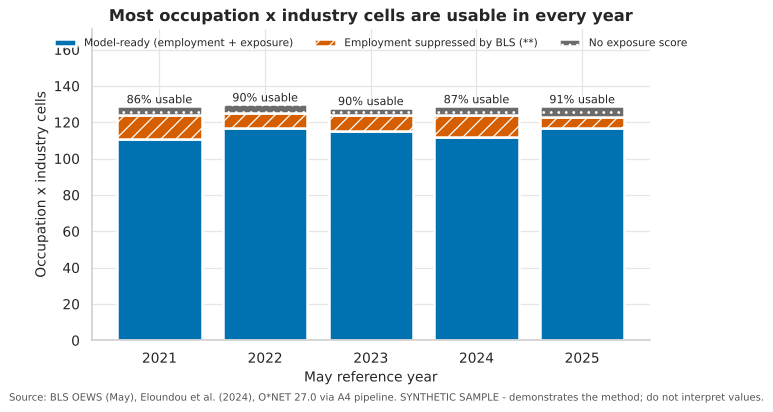

In [3]:
plots.plot_coverage(qc.coverage, FIG / "fig01_data_coverage.png", panel.attrs["source_mode"]);

**Reading.** The key is unique, years are complete, BLS suppression flags agree with NULL values, and exposures are in range. One panel occupation (Construction Laborers, 47-2061) has no exposure score; it is kept in the panel but drops out of exposure analyses (~5% of rows). Between 86% and 91% of cells are model-ready each year; the rest are lost mainly to BLS employment suppression (`**`), so trend views below use a **balanced** set of cells to keep composition fixed.

## 2. Univariate analysis

In [4]:
display(describe.univariate_summary(panel, ["tot_emp", "log_emp", "a_mean", "log_wage",
                                             "exposure_main", "job_zone_mean", "emp_prse", "mean_prse"]))
occ = describe.occupation_table(panel)
display(occ[["occ_title", "exposure_main", "job_zone_mean", "exposure_group", "exposure_tercile",
             "pre_emp_total", "pre_mean_wage"]])

,n,missing_share,mean,sd,min,p25,median,p75,max,skew,excess_kurtosis
tot_emp,597.0000,0.0740,"2,789.3920","3,801.8818",186.0000,737.0000,"1,324.0000","3,433.0000","30,816.0000",3.5714,16.4566
log_emp,597.0000,0.0740,7.3701,1.0233,5.2257,6.6026,7.1884,8.1412,10.3358,0.3726,-0.3529
a_mean,628.0000,0.0260,"91,029.2516","43,299.7245","32,970.0000","48,325.0000","94,330.0000","116,982.5000","229,540.0000",0.6362,-0.1338
log_wage,628.0000,0.0260,11.3016,0.4937,10.4034,10.7857,11.4546,11.6698,12.3438,-0.0779,-1.2470
exposure_main,615.0000,0.0470,0.6643,0.2361,0.0500,0.5800,0.7400,0.8000,0.9500,-1.3340,1.1234
job_zone_mean,645.0000,0.0000,3.2233,1.1297,1.0000,2.0000,4.0000,4.0000,5.0000,-0.2842,-1.0156
emp_prse,645.0000,0.0000,12.7614,6.6192,1.1000,7.3000,12.4000,18.4000,25.0000,0.0811,-1.1228
mean_prse,645.0000,0.0000,3.3214,1.5613,0.5000,2.0000,3.3000,4.6000,6.0000,-0.0530,-1.1213


,occ_title,exposure_main,job_zone_mean,exposure_group,exposure_tercile,pre_emp_total,pre_mean_wage
soc_code,,,,,,,
43-9021,Data Entry Keyers,0.9500,2.0000,High,High,"11,449.0000","42,441.3333"
15-1252,Software Developers,0.9000,4.0000,High,High,"7,651.5000","145,721.8182"
43-3031,"Bookkeeping, Accounting, and Auditing Clerks",0.9000,3.0000,High,High,"10,950.0000","49,570.8333"
13-2051,Financial and Investment Analysts,0.8400,4.0000,High,High,"12,039.5000","109,049.2857"
13-2041,Credit Analysts,0.8000,4.0000,High,High,"11,742.0000","89,564.0000"
15-2031,Operations Research Analysts,0.7900,5.0000,High,High,"11,706.5000","100,215.0000"
13-2011,Accountants and Auditors,0.7800,4.0000,High,Middle,"30,865.5000","91,361.8750"
23-2011,Paralegals and Legal Assistants,0.7700,3.0000,High,Middle,"8,514.0000","66,310.0000"
43-4051,Customer Service Representatives,0.7400,2.0000,Low,Middle,"30,802.5000","44,503.3333"


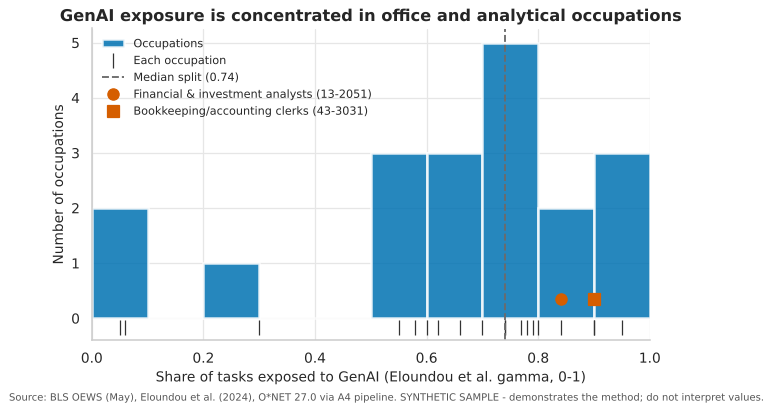

In [5]:
plots.plot_exposure_distribution(occ, panel.attrs["exposure_median"], FIG / "fig02_exposure_distribution.png",
                                 panel.attrs["source_mode"]);

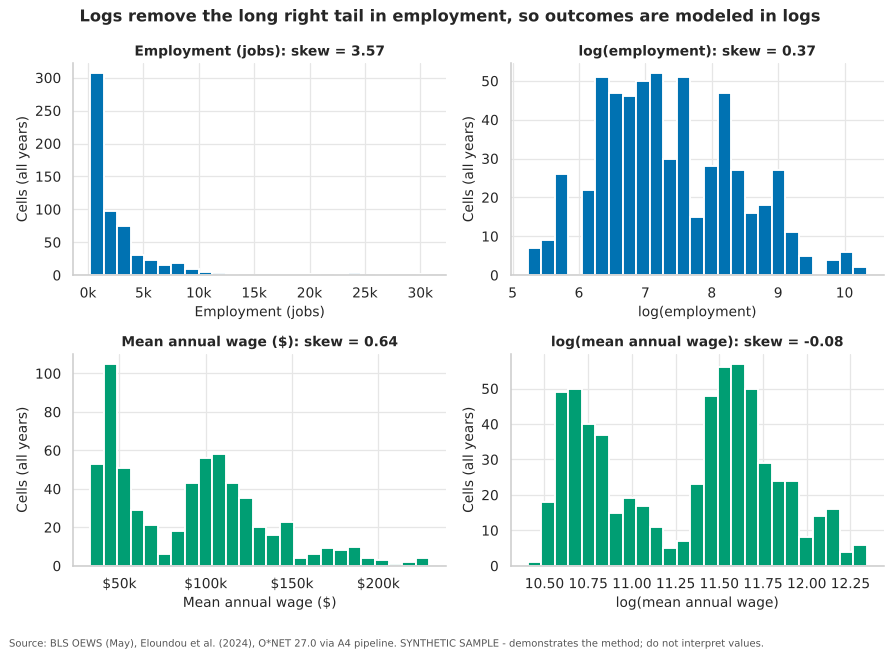

In [6]:
plots.plot_outcome_distributions(panel, FIG / "fig03_outcome_distributions.png", panel.attrs["source_mode"]);

**Reading.**
* Employment is strongly right-skewed (skew ≈ 3.6, a few very large cells); its log is close to symmetric (≈ 0.4). Wages are bimodal (low-wage service/clerical vs. professional occupations) and the log removes the remaining skew. This confirms the A3 choice to model **log** employment and **log** mean wage.
* Exposure is left-skewed: most occupations in this finance-focused panel sit between 0.55 and 0.95; manual occupations anchor the low end. The median occupation exposure (0.74) defines the High/Low split; both focal occupations (analysts 0.84, clerks 0.90) are High.
* Relative standard errors (EMP_PRSE, MEAN_PRSE) are available for every cell, so imprecise cells can be down-weighted or dropped in A6 sensitivity checks.

## 3. Bivariate analysis: exposure vs. change after ChatGPT

`describe.cell_changes()` collapses each occupation × industry cell to *mean post-period log outcome − mean pre-period log outcome* (pre = 2021-22, post = 2023+). This is the cell-level analogue of the A3 difference-in-differences contrast and tolerates a suppressed year.

In [7]:
cells = describe.cell_changes(panel)
print("Employment change (approx. %), by exposure group:")
display(describe.group_comparison(cells, "d_log_emp"))
print("Wage change (approx. %), by exposure group:")
display(describe.group_comparison(cells, "d_log_wage"))
print("Cell-level correlation, exposure vs employment change:", describe.correlation_with_pvalues(cells, "exposure_main", "d_log_emp"))
print("Cell-level correlation, exposure vs wage change:      ", describe.correlation_with_pvalues(cells, "exposure_main", "d_log_wage"))

Employment change (approx. %), by exposure group:


,n,mean,median,sd,approx_pct_change
exposure_group,,,,,
High,53,0.0265,0.0287,0.0297,2.6825
Low,70,0.0546,0.0536,0.0406,5.6140


Wage change (approx. %), by exposure group:


,n,mean,median,sd,approx_pct_change
exposure_group,,,,,
High,53,0.0815,0.0788,0.0386,8.4894
Low,71,0.0819,0.0858,0.0417,8.5390


Cell-level correlation, exposure vs employment change: {'n': 123, 'pearson_r': -0.6143511663187667, 'pearson_p': 4.112316686780053e-14, 'spearman_rho': -0.5189894333215862, 'spearman_p': 7.758914002063475e-10}
Cell-level correlation, exposure vs wage change:       {'n': 124, 'pearson_r': -0.0067679414037843085, 'pearson_p': 0.9405312360414957, 'spearman_rho': -0.009538792998339353, 'spearman_p': 0.9162598566143001}


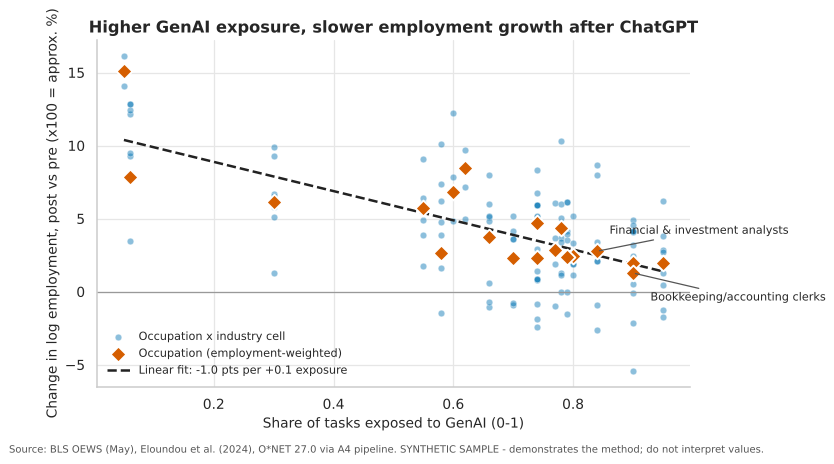

In [8]:
occ_emp = describe.occupation_changes(cells, "d_log_emp")
plots.plot_exposure_vs_change(cells, occ_emp, "d_log_emp", FIG / "fig04_exposure_vs_emp_change.png",
                              panel.attrs["source_mode"]);

group,High,Low,Middle
year,,,
2021,99.5213,98.7584,97.4600
2022,100.0000,100.0000,100.0000
2023,102.4986,103.2663,100.9787
2024,101.9584,107.0930,101.8727
2025,102.3052,111.6434,103.1380


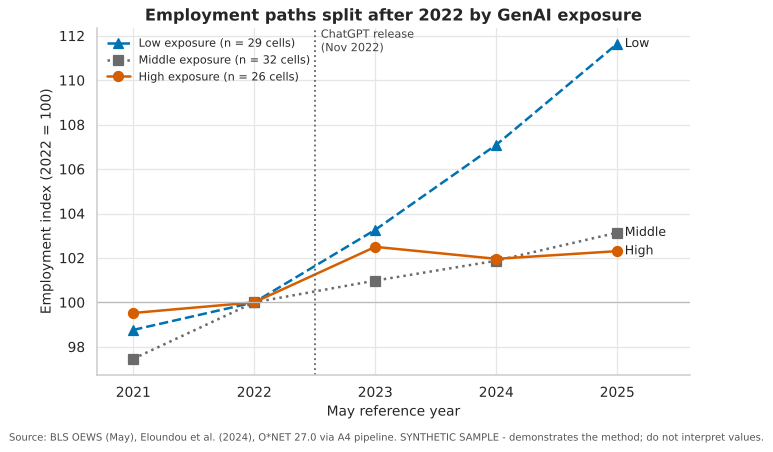

In [9]:
balanced = data.balanced_cells(panel, "log_emp")
trend = describe.trend_index(balanced, "exposure_tercile", "log_emp")
display(trend.pivot(index="year", columns="group", values="index"))
plots.plot_trend_index(trend, "Employment", FIG / "fig05_emp_trend_by_exposure.png", panel.attrs["source_mode"]);

**Reading.** Employment in high-exposure cells grew roughly half as fast as in low-exposure cells after 2022 (≈ +2.7% vs ≈ +5.6%), and the scatter shows a clear downward slope. The balanced-panel trend matters for the A6 design: the three exposure terciles move roughly together through 2022 (pre-trends look approximately parallel) and separate only afterwards. Wage changes show **no** relationship with exposure (r ≈ 0).

## 4. Multivariate analysis

Two questions: (a) how do exposure, preparation (Job Zone), pay and size relate to each other? (b) Does the exposure-employment association survive controls for preparation, pre-period pay and industry? Standard errors are clustered by occupation (CR1, G − 1 df), because exposure varies only across occupations.

,exposure_main,job_zone_mean,pre_log_wage,pre_log_emp,d_log_emp,d_log_wage
exposure_main,1.0000,0.1688,-0.0688,-0.0424,-0.5190,-0.0095
job_zone_mean,0.1688,1.0000,0.8085,-0.0818,-0.2737,0.1357
pre_log_wage,-0.0688,0.8085,1.0000,-0.1322,-0.1541,0.0208
pre_log_emp,-0.0424,-0.0818,-0.1322,1.0000,0.0195,0.0269
d_log_emp,-0.5190,-0.2737,-0.1541,0.0195,1.0000,0.0264
d_log_wage,-0.0095,0.1357,0.0208,0.0269,0.0264,1.0000


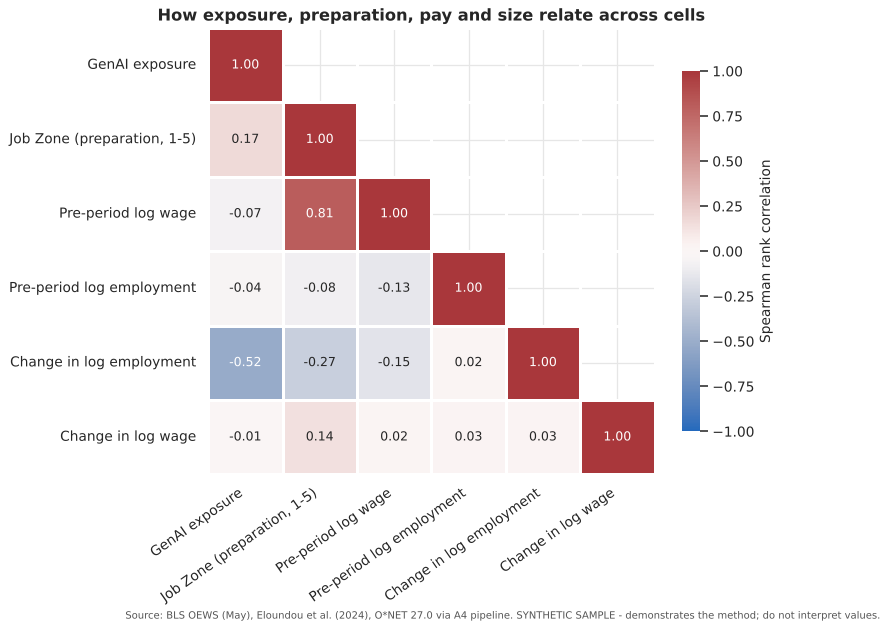

In [10]:
corr_cols = ["exposure_main", "job_zone_mean", "pre_log_wage", "pre_log_emp", "d_log_emp", "d_log_wage"]
corr = describe.correlation_table(cells, corr_cols)
display(corr)
from oews_eda.report import LABELS
plots.plot_correlation_heatmap(corr, LABELS, FIG / "fig06_correlation_heatmap.png", panel.attrs["source_mode"]);

In [11]:
X = ["exposure_z", "job_zone_mean", "pre_log_wage"]
print("Multicollinearity check (VIF; < 5 acceptable):")
display(inference.vif(cells, X).to_frame())
m_emp = inference.ols_cluster(cells, "d_log_emp", X, fixed_effects=["naics_code"])
m_wage = inference.ols_cluster(cells, "d_log_wage", X, fixed_effects=["naics_code"])
for m in (m_emp, m_wage):
    print(f"\n{m.formula}   n = {m.n_obs}, occupation clusters = {m.n_clusters}, R² = {m.r2:.3f}")
    display(m.table)

Multicollinearity check (VIF; < 5 acceptable):


,VIF
exposure_z,1.3889
job_zone_mean,4.3814
pre_log_wage,3.7964



d_log_emp ~ exposure_z + job_zone_mean + pre_log_wage | FE: naics_code   n = 123, occupation clusters = 19, R² = 0.453


,coef,se_cluster,t,p_value,ci_low,ci_high
const,0.2095,0.1312,1.5969,0.1277,-0.0661,0.4852
exposure_z,-0.0258,0.0039,-6.5917,0.0000,-0.0341,-0.0176
job_zone_mean,0.0046,0.0050,0.9087,0.3755,-0.0060,0.0151
pre_log_wage,-0.0149,0.0131,-1.1369,0.2705,-0.0425,0.0127



d_log_wage ~ exposure_z + job_zone_mean + pre_log_wage | FE: naics_code   n = 124, occupation clusters = 19, R² = 0.106


,coef,se_cluster,t,p_value,ci_low,ci_high
const,0.2496,0.1053,2.3702,0.0292,0.0284,0.4708
exposure_z,-0.0042,0.0030,-1.3977,0.1792,-0.0105,0.0021
job_zone_mean,0.0122,0.0051,2.3775,0.0287,0.0014,0.0230
pre_log_wage,-0.0177,0.0106,-1.6715,0.1119,-0.0400,0.0045


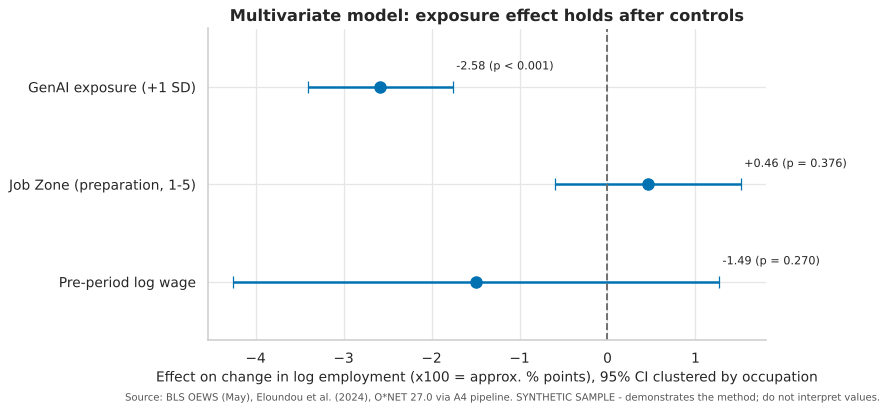

In [12]:
plots.plot_coefficients(m_emp.table, LABELS, path=FIG / "fig07_model_coefficients.png",
                        source_mode=panel.attrs["source_mode"]);

**Reading.** Job Zone and pre-period wage are highly correlated with each other (ρ ≈ 0.8, VIF ≈ 4), but neither is strongly correlated with exposure (|ρ| ≤ 0.17), so exposure is not simply proxying for skill or pay. With industry fixed effects and those controls, a one-standard-deviation increase in exposure is associated with about **2.6 percentage points less employment growth** (95% CI clustered by occupation excludes zero). The wage model shows no exposure association; preparation (Job Zone) is the only wage predictor. Industry fixed effects absorb sector-wide shocks, which previews the industry-by-year fixed effects in the A3 specification.

## 5. Hypothesis tests

### 5.1 Employment (A3 H1, one-sided)

* **H₀:** μ_High − μ_Low ≥ 0 — high-exposure cells' employment grew at least as fast as low-exposure cells' after 2022.
* **H₁:** μ_High − μ_Low < 0 — high-exposure cells' employment grew more slowly.
* **α = 0.05.** Unit: occupation × industry cell; outcome: change in log employment (post − pre).

**Assumptions checked:** normality within each group (Shapiro-Wilk + Q-Q plots), equal variances (Levene, median-centred), independence. Independence is the weak point: cells of the same occupation share one exposure score, so the test is paired with (i) an occupation-cluster bootstrap CI and (ii) an occupation-level permutation test (n = occupations). Mann-Whitney U is reported as a distribution-free check.

In [13]:
t_emp = inference.exposure_group_test(cells, "d_log_emp", alternative="less")
display(pd.Series(t_emp.assumptions, name="assumption checks").to_frame())
print(f"{t_emp.test_used}: t = {t_emp.statistic:.3f}, p = {t_emp.p_value:.2e}  ->  {t_emp.decision}")
print(f"Hedges' g = {t_emp.hedges_g:.2f};  Mann-Whitney p = {t_emp.mann_whitney_p:.2e}")
print(f"Occupation-cluster bootstrap 95% CI for the gap (log points): [{t_emp.cluster_ci_low:.4f}, {t_emp.cluster_ci_high:.4f}]")
print("Occupation-level permutation test:", inference.occupation_permutation_test(occ_emp, alternative="less"))
print()
print(t_emp.interpretation)

,assumption checks
n_a,53
n_b,70
shapiro_a_W,0.9891
shapiro_a_p,0.9082
shapiro_b_W,0.9762
shapiro_b_p,0.2043
levene_W,3.5375
levene_p,0.0624
normal_or_large_n,True
equal_variances,True


Student's t: t = -4.258, p = 2.05e-05  ->  Reject H0
Hedges' g = -0.77;  Mann-Whitney p = 1.82e-05
Occupation-cluster bootstrap 95% CI for the gap (log points): [-0.0469, -0.0122]
Occupation-level permutation test: {'n_occupations': 19, 'spearman_rho': -0.7945569348515471, 'p_value': 9.999000099990002e-05, 'alternative': 'less', 'n_permutations': 10000}

High-exposure cells' employment grew about 2.8% less than low-exposure cells' between the pre and post periods (Hedges' g = -0.77). The gap is statistically distinguishable from zero at the 5% level, and the occupation-cluster bootstrap CI also excludes zero, so the result does not rest on treating cells of the same occupation as independent.


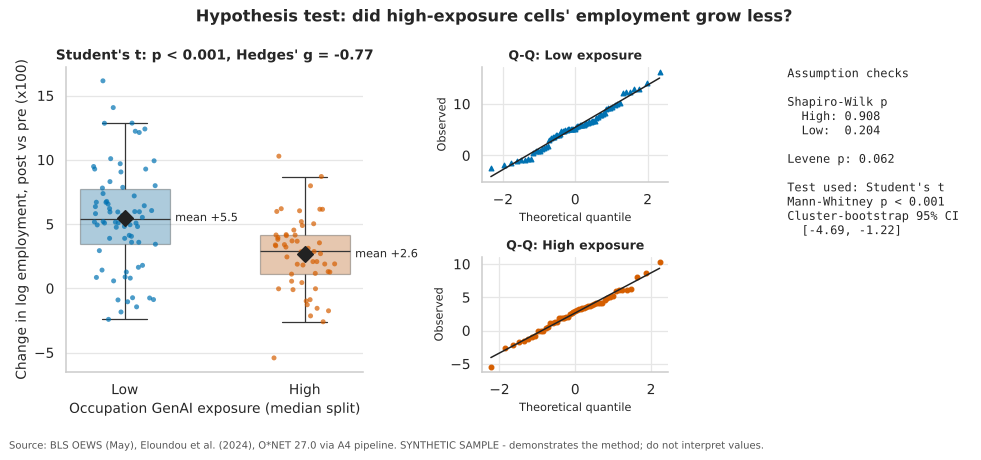

In [14]:
plots.plot_group_test(cells, "d_log_emp", t_emp, FIG / "fig08_hypothesis_test_emp.png", panel.attrs["source_mode"]);

**Interpretation.** Both groups pass the normality check (Shapiro-Wilk p > 0.05, straight Q-Q plots) and Levene does not reject equal variances (p ≈ 0.06, borderline), so Student's t applies; Welch's t gives the same conclusion. We **reject H₀**: high-exposure cells' employment grew about 2.8% less than low-exposure cells', a medium-to-large effect (g ≈ −0.8). The conclusion does not depend on treating cells as independent: the occupation-cluster bootstrap CI excludes zero and the occupation-level permutation test (19 occupations) is also significant. Mann-Whitney agrees, so the result is not driven by outliers.

### 5.2 Wages (two-sided) and the delayed-post robustness check

* **H₀:** μ_High − μ_Low = 0 for the change in log mean wage; **H₁:** ≠ 0.
* Robustness (A3): repeat the employment test with the delayed post period (2024+), in case adoption lagged ChatGPT's release.

In [15]:
t_wage = inference.exposure_group_test(cells, "d_log_wage", alternative="two-sided")
print(f"WAGES  {t_wage.test_used}: p = {t_wage.p_value:.3f}, g = {t_wage.hedges_g:.2f}, cluster CI "
      f"[{t_wage.cluster_ci_low:.4f}, {t_wage.cluster_ci_high:.4f}] -> {t_wage.decision}")
print(t_wage.interpretation)
cells_delayed = describe.cell_changes(panel, post_col="post_delayed")
t_del = inference.exposure_group_test(cells_delayed, "d_log_emp", alternative="less")
print(f"\nEMPLOYMENT, delayed post (2024+): p = {t_del.p_value:.2e}, g = {t_del.hedges_g:.2f}, "
      f"gap = {t_del.diff_pct_points:.1f}% -> {t_del.decision}")

WAGES  Student's t: p = 0.950, g = -0.01, cluster CI [-0.0117, 0.0092] -> Fail to reject H0
High- and low-exposure cells' mean wages changed by virtually the same amount between the pre and post periods (gap -0.05%, Hedges' g = -0.01). The gap is not statistically distinguishable from zero at the 5% level (the occupation-cluster bootstrap CI also includes zero).

EMPLOYMENT, delayed post (2024+): p = 8.97e-09, g = -1.09, gap = -4.0% -> Reject H0


**Interpretation.** We **fail to reject H₀** for wages: there is no detectable wage difference between high- and low-exposure cells (g ≈ 0, CI spans zero). With the delayed post period the employment gap is *larger* (≈ −4% vs ≈ −2.8%), which is what a gradually building adoption effect would look like and supports the A3 plan to estimate event-time coefficients rather than a single post dummy.

## 6. Finance contrast (descriptive only, per A3 feedback)

Financial & investment analysts (13-2051) vs. bookkeeping, accounting & auditing clerks (43-3031), each on its industry cells observed in every year, indexed to 2022 = 100. With only 2-3 industries per role this is context, not a test.

,focal_role,year,total_emp,mean_wage,n_industries,emp_index,wage_index
0,analyst,2021,"9,700.0000","109,016.6667",3,100.4557,98.4379
1,analyst,2022,"9,656.0000","110,746.6667",3,100.0000,100.0000
2,analyst,2023,"9,645.0000","117,540.0000",3,99.8861,106.1341
3,analyst,2024,"9,892.0000","117,433.3333",3,102.4441,106.0378
4,analyst,2025,"10,121.0000","126,833.3333",3,104.8157,114.5256
5,clerk_contrast,2021,"1,802.0000","55,705.0000",2,101.6930,105.1236
6,clerk_contrast,2022,"1,772.0000","52,990.0000",2,100.0000,100.0000
7,clerk_contrast,2023,"1,861.0000","57,035.0000",2,105.0226,107.6335
8,clerk_contrast,2024,"1,853.0000","60,165.0000",2,104.5711,113.5403
9,clerk_contrast,2025,"1,902.0000","62,160.0000",2,107.3363,117.3052


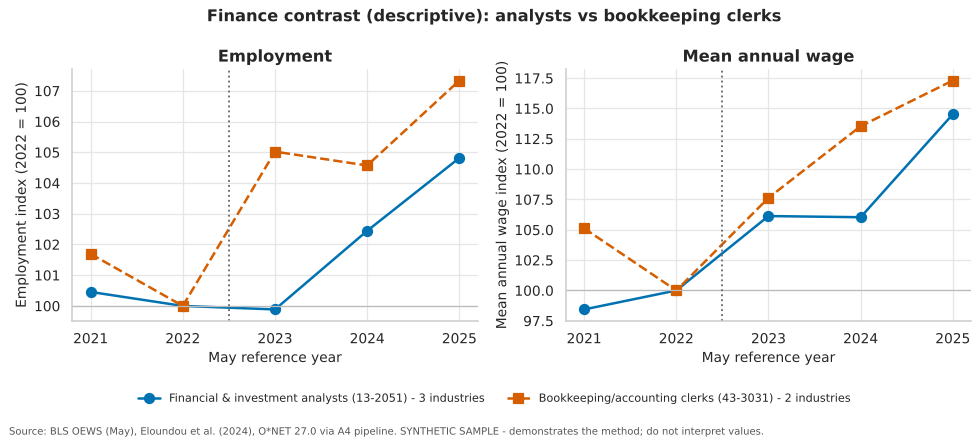

In [16]:
contrast = describe.focal_contrast(panel)
display(contrast)
plots.plot_focal_contrast(contrast, FIG / "fig09_analyst_vs_clerk.png", panel.attrs["source_mode"]);

**Reading.** In the sample both roles grow after 2022, and the cross-occupation slope in Section 3 places both near the high-exposure end of the fitted line. Whether GenAI complements analysts' tasks while substituting for clerks' is a hypothesis this EDA cannot test with 2-3 industries per role; the A6 analyst-by-post interaction is where the contrast will be quantified, so here it stays descriptive.

## 7. Findings, business implications, and what they mean for modeling

| # | Finding (sample run) | Business implication | Implication for A6 modeling |
|---|---|---|---|
| 1 | Employment grew ~2.8% less in high-exposure cells after 2022; holds with controls, industry FE, occupation clustering, and nonparametric tests | Workforce plans for GenAI-exposed roles (analysts, accountants, data entry, developers) should assume slower headcount growth, not flat-line growth | Main TWFE β on employment is expected negative; keep occupation-clustered SEs |
| 2 | The gap widens with the delayed post (2024+) | Effects build over time; one year of post data understates them | Estimate event-time coefficients (2022 reference), not only a single post dummy |
| 3 | No wage difference by exposure | Exposure is changing *how many* people are hired before it changes *what they are paid*; pay benchmarks do not need a GenAI discount yet | Wage outcome stays two-sided; expect a null or small β |
| 4 | Pre-period trends by exposure tercile are parallel | Comparisons between high- and low-exposure roles are credible | Supports the DiD identifying assumption; test formally with pre-period event-time coefficients |
| 5 | Exposure is nearly uncorrelated with preparation and pay | GenAI exposure is a distinct risk dimension, not a proxy for "high-skill" or "high-pay" | Job Zone can be a moderator, not a confounder; VIFs < 5 |
| 6 | 9-14% of cells per year are lost to suppression | Small occupation-industry cells are under-represented | Report balanced vs unbalanced estimates; weight or drop high-PRSE cells in sensitivity |

The non-technical version is in `docs/A5_EXECUTIVE_SUMMARY.md`.

## 8. Regenerate every output in one call

`report.run_all()` re-runs everything above and writes the figures (`reports/figures/`), tables and a JSON summary (`reports/eda/`). The same entry point is available as `uv run oews-eda`.

In [17]:
from oews_eda import report
summary = report.run_all()
print("Figures:", sorted(p.name for p in FIG.glob("fig*.png")))
print("Headline:", summary["test_emp"]["decision"], "| employment gap (approx. %):",
      round(summary["test_emp"]["diff_pct_points"], 2), "| data:", summary["source_mode"])

Figures: ['fig01_data_coverage.png', 'fig02_exposure_distribution.png', 'fig03_outcome_distributions.png', 'fig04_exposure_vs_emp_change.png', 'fig05_emp_trend_by_exposure.png', 'fig06_correlation_heatmap.png', 'fig07_model_coefficients.png', 'fig08_hypothesis_test_emp.png', 'fig09_analyst_vs_clerk.png']
Headline: Reject H0 | employment gap (approx. %): -2.78 | data: sample
